In [27]:
import pandas as pd
import matplotlib.pyplot as plt 
import thesis_style as ts 
import numpy as np 
ts.use()

In [2]:
o2_results = pd.read_csv('port-S_o2.csv')
o4_results  = pd.read_csv('port-S.csv')

In [3]:
o2_results

,f (GHz),|S[1][1]| (dB),arg(S[1][1]) (deg.),|S[2][1]| (dB),arg(S[2][1]) (deg.)
0,2.0,-7.022639,166.338855,-6.043865,-27.534550
1,4.0,-9.146990,159.150930,-6.549143,-52.649689
2,6.0,-11.798936,165.411748,-6.955019,-75.120242
3,8.0,-12.524021,-173.622642,-7.032485,-96.316437
4,10.0,-10.264415,-160.156727,-6.744459,-118.059212
5,12.0,-7.756003,-162.691552,-6.240640,-141.998458
6,14.0,-6.361143,-174.440770,-5.851226,-168.715325
7,16.0,-6.487449,171.129482,-5.894543,163.405011
8,18.0,-8.088760,160.491211,-6.328744,137.153450
9,20.0,-10.659809,160.148884,-6.804732,113.696204


In [4]:
o4_results

,f (GHz),|S[1][1]| (dB),arg(S[1][1]) (deg.),|S[2][1]| (dB),arg(S[2][1]) (deg.)
0,2.0,-7.330960,163.824592,-5.919451,-28.029482
1,4.0,-9.776920,154.581557,-6.547731,-53.013812
2,6.0,-13.084601,160.355059,-7.050962,-74.779984
3,8.0,-14.313467,-173.251338,-7.165093,-94.987612
4,10.0,-11.485443,-155.729193,-6.841390,-115.711479
5,12.0,-8.434894,-158.442726,-6.228899,-138.924662
6,14.0,-6.682710,-171.872788,-5.704497,-165.621479
7,16.0,-6.648802,171.059743,-5.700149,165.858599
8,18.0,-8.334031,157.407662,-6.219613,139.116169
9,20.0,-11.328835,154.090828,-6.833202,115.851724


In [13]:
columns = o4_results.columns
columns

Index(['        f (GHz)', '             |S[1][1]| (dB)',
       '        arg(S[1][1]) (deg.)', '             |S[2][1]| (dB)',
       '        arg(S[2][1]) (deg.)'],
      dtype='str')

In [28]:
frequencies = o4_results[columns[0]].to_numpy(dtype = float)
o2_s11_mag = o2_results[columns[1]].to_numpy(dtype = float)
o4_s11_mag = o4_results[columns[1]].to_numpy(dtype = float)
o2_s11_arg = o2_results[columns[2]].to_numpy(dtype = float)
o4_s11_arg = o4_results[columns[2]].to_numpy(dtype = float)

o2_s21_mag = o2_results[columns[3]].to_numpy(dtype = float)
o4_s21_mag = o4_results[columns[3]].to_numpy(dtype = float)
o2_s21_arg = o2_results[columns[4]].to_numpy(dtype = float)
o4_s21_arg = o4_results[columns[4]].to_numpy(dtype = float)

complex_s11_o2 = o2_s11_mag * np.exp(1.0j * o2_s11_arg)
complex_s11_o4 = o4_s11_mag * np.exp(1.0j * o4_s11_arg)
complex_s11_o2 = o2_s21_mag * np.exp(1.0j * o2_s21_arg)
complex_s21_o4 = o4_s21_mag * np.exp(1.0j * o4_s21_arg)

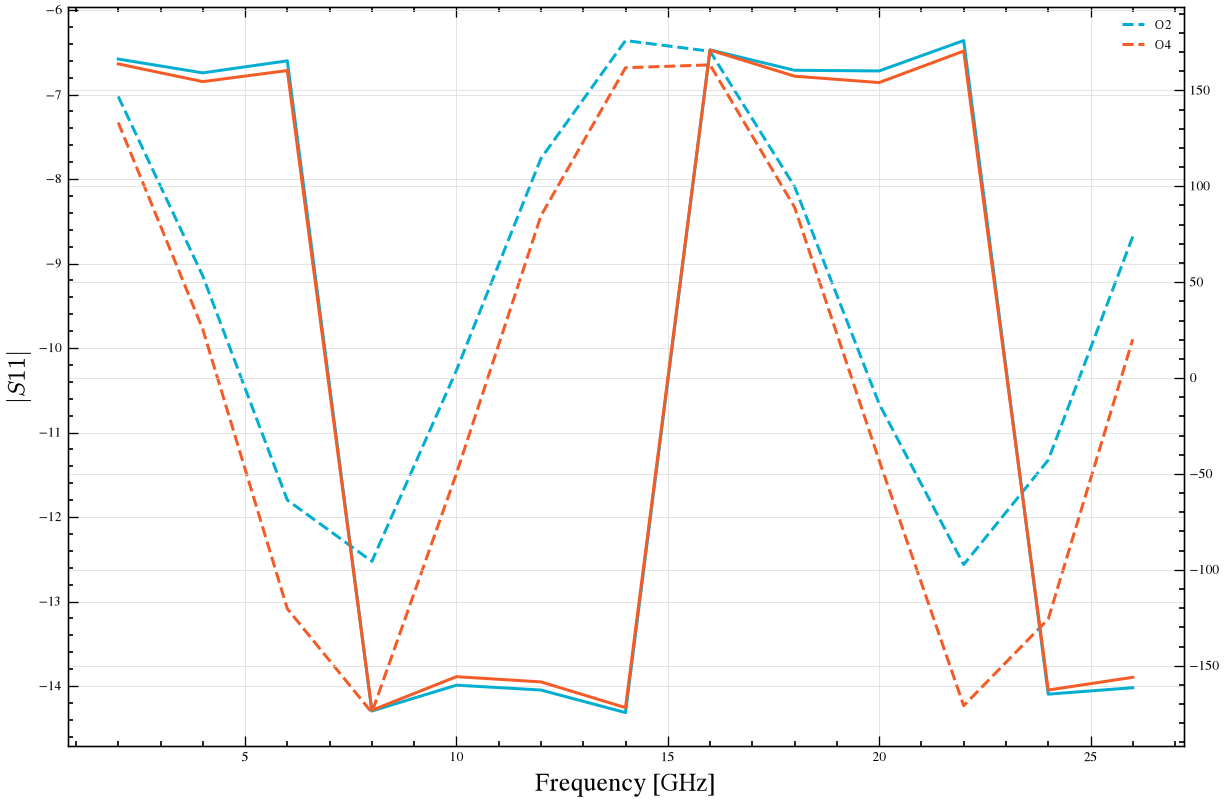

In [25]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12, 8))

ax.plot(frequencies, o2_s11_mag, label = 'O2', linestyle = 'dashed')
ax.plot(frequencies, o4_s11_mag, label = 'O4', linestyle = 'dashed')
ax.set_xlabel('Frequency [GHz]', fontsize = 15)
ax.set_ylabel(r'$\vert S11 \vert$', fontsize = 15)

ax2 = plt.twinx(ax)
ax2.plot(frequencies, o2_s11_arg)
ax2.plot(frequencies, o4_s11_arg)
ax.legend()

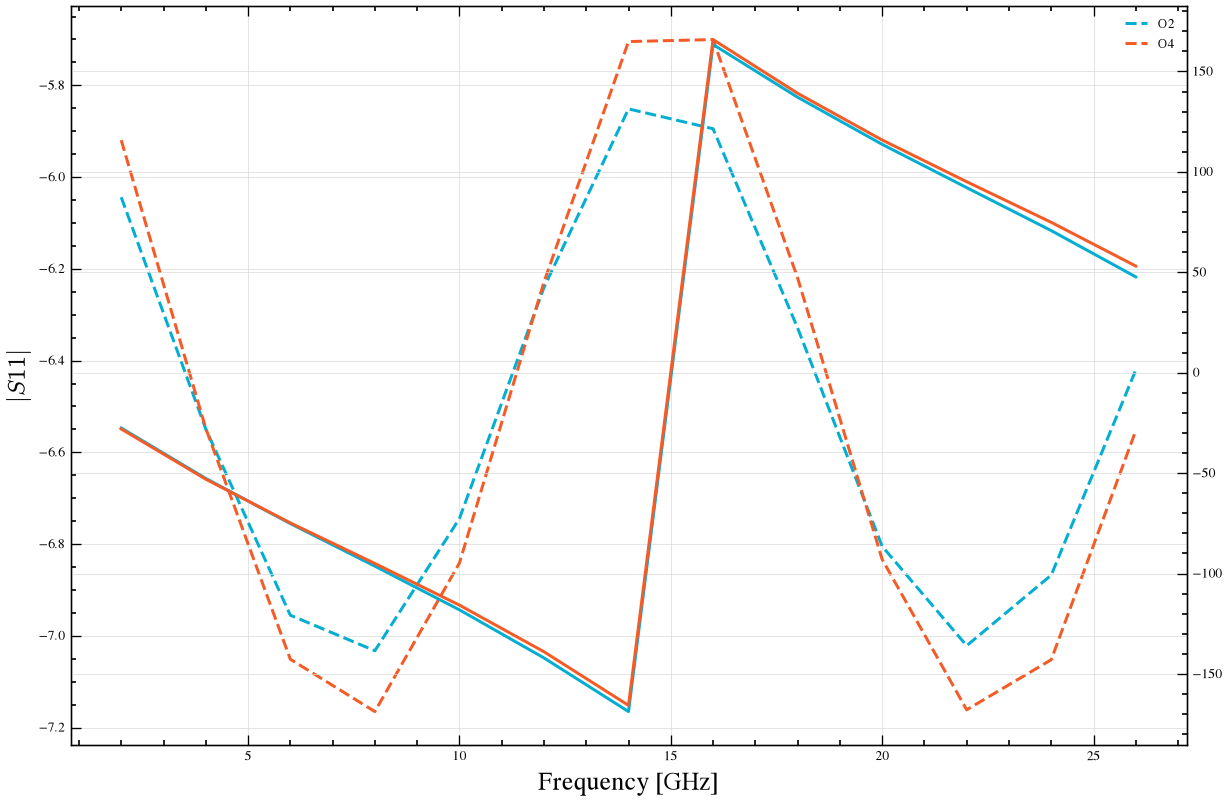

In [26]:
fig, ax = plt.subplots(nrows = 1, ncols = 1, figsize = (12, 8))

ax.plot(frequencies, o2_s21_mag, label = 'O2', linestyle = 'dashed')
ax.plot(frequencies, o4_s21_mag, label = 'O4', linestyle = 'dashed')
ax.set_xlabel('Frequency [GHz]', fontsize = 15)
ax.set_ylabel(r'$\vert S11 \vert$', fontsize = 15)

ax2 = plt.twinx(ax)
ax2.plot(frequencies, o2_s21_arg)
ax2.plot(frequencies, o4_s21_arg)
ax.legend()

In [29]:
complex_impedance_o2 = 50.0 * (1- complex_s11_o2) / (1 + complex_s11_o2)
complex_impedance_o4 = 50.0 * (1- complex_s11_o4) / (1 + complex_s11_o4)

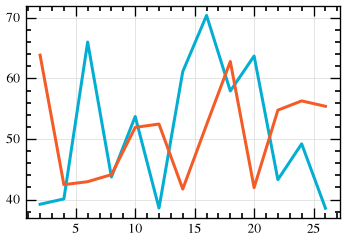

In [31]:
plt.plot(frequencies, np.abs(complex_impedance_o2))
plt.plot(frequencies, np.abs(complex_impedance_o4))

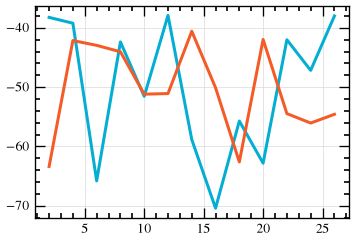

In [ ]:
plt.plot(frequencies, np.real(complex_impedance_o2))
plt.plot(frequencies, np.real(complex_impedance_o4))

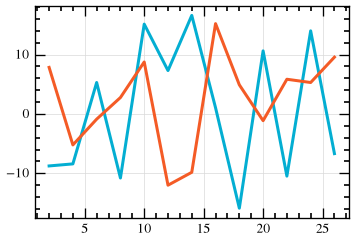

In [33]:
plt.plot(frequencies, np.imag(complex_impedance_o2))
plt.plot(frequencies, np.imag(complex_impedance_o4))

In [36]:
dir = '/home/ruiz/Documents/thesis/notebooks/design/parametric_coupling_chip/julia_test/'
data = pd.read_csv(dir + 'port-S.csv')
cols =data.columns
data

,f (GHz),|S[1][1]| (dB),arg(S[1][1]) (deg.),|S[2][1]| (dB),arg(S[2][1]) (deg.)
0,2.0,-10.621327,132.074488,-4.335423,-33.133835
1,4.0,-13.437671,87.903648,-5.672113,-58.653981
2,6.0,-16.351889,40.135323,-6.592825,-78.064754
3,8.0,-17.141277,-16.789133,-6.756028,-95.127873
4,10.0,-14.841758,-69.545759,-6.125517,-113.165806
5,12.0,-11.738931,-114.538566,-4.881128,-135.754997
6,14.0,-9.602861,-160.850958,-3.741700,-166.092952
7,16.0,-9.760470,150.480112,-3.885636,159.438705
8,18.0,-12.035720,105.728867,-5.128843,130.623677
9,20.0,-15.106548,61.851908,-6.277438,109.173080


In [38]:
frequencies = data[cols[0]].to_numpy(dtype = float)
s11_mag = data[cols[1]].to_numpy(dtype = float)
s11_arg = data[cols[2]].to_numpy(dtype = float)

s21_mag = data[cols[3]].to_numpy(dtype = float)
s21_arg = data[cols[4]].to_numpy(dtype = float)

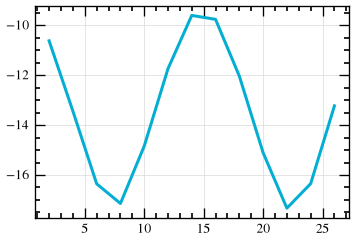

In [ ]:
plt.plot(frequencies, s11_mag)


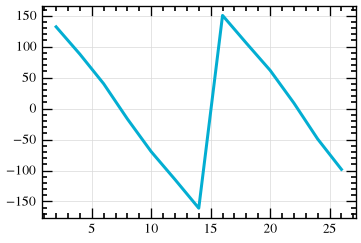

In [41]:
plt.plot(frequencies, s11_arg)

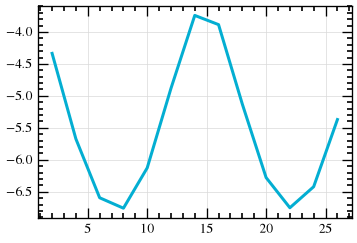

In [42]:
plt.plot(frequencies, s21_mag)

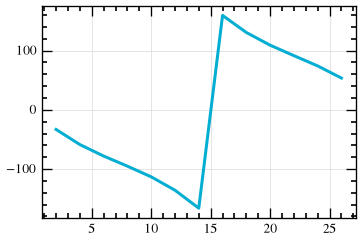

In [43]:
plt.plot(frequencies, s21_arg)

In [44]:
new_data = np.load('/home/ruiz/Documents/thesis/notebooks/design/parametric_coupling_chip/julia_test/verified_w10s6_s21.npz')

In [45]:
new_data.files

['freq_hz', 'S11', 'S21']

In [46]:
freq = new_data['freq_hz']
s11 = new_data['S11']
s21 = new_data['S21']

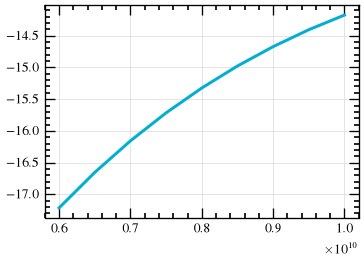

In [47]:
plt.plot(freq, 20.0 * np.log10(np.abs(s11)))

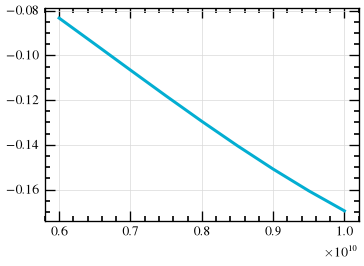

In [48]:
plt.plot(freq, 20.0 * np.log10(np.abs(s21)))

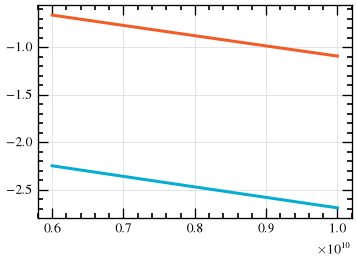

In [ ]:
plt.plot(freq, np.angle(s11))
plt.plot(freq, np.angle(s21))